## Starter Code

In [1]:
import torch
import torch.nn as nn
from torchvision import models, transforms

# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
    
# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
for param in model.layer4.parameters():
    param.requires_grad = True

# Optimasi dengan Differential Learning Rate
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(),
    "lr": 1e-4},
    {"params": model.fc.parameters(),
    "lr": 1e-3},
], weight_decay=1e-2)

# 4. Pipeline Transformasi Data
# Data latih: menerapkan augmentasi aktif
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean,
std=weights.transforms().std),
])

# Data validasi/uji: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()

# Verifikasi parameter yang dapat dilatih
trainable_params = sum(p.numel() for p in model.parameters() if
p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s] 


Trainable Parameters: 8,398,858 / 11,181,642


In [2]:
import numpy as np
import torchvision
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

In [3]:
# 1) download dataset (Oxford-IIIT Pet)
df = torchvision.datasets.OxfordIIITPet(root='./data', split='trainval', download=True)

100%|██████████| 792M/792M [00:21<00:00, 37.5MB/s] 
100%|██████████| 19.2M/19.2M [00:01<00:00, 17.3MB/s]


In [4]:
# 2) Tampilkan informasi dataset
print(f"Total gambar dalam dataset: {len(df)}")
print(f"Total kelas: {len(df.classes)}")
print(f"Categories: {df.classes}")

Total gambar dalam dataset: 3680
Total kelas: 37
Categories: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


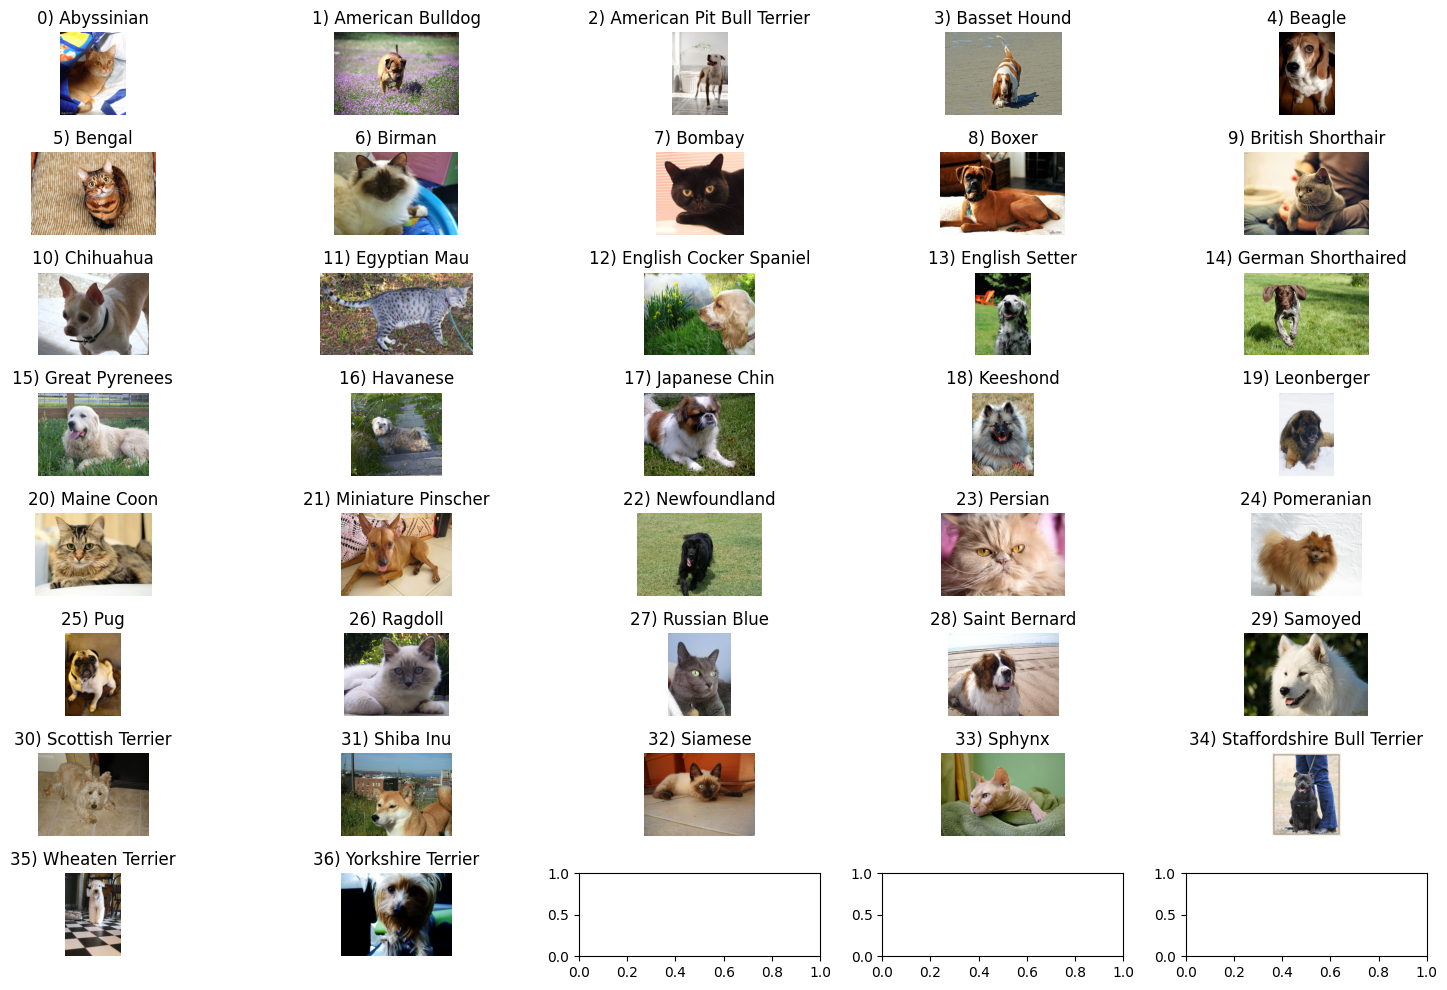

In [5]:
import matplotlib.pyplot as plt

all_sample_image = {}
for img, target in df:
    if target not in all_sample_image:
        all_sample_image[target] = img
    if len(all_sample_image) == len(df.classes):
        break

fig, axes = plt.subplots(8, 5, figsize=(15, 10))
axes = axes.flatten()

for i in range(len(df.classes)):
    img = all_sample_image[i]
    axes[i].imshow(img)
    axes[i].set_title(f"{i}) {df.classes[i]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [6]:
# Ambil subset 10 Kelas (5 kucing dan 5 anjing)
kucing = [0,5,6,7,11]
anjing = [1,2,3,15,31]
selected_class = kucing + anjing

len(selected_class)

10

In [7]:
x = []
y = []

for idx, (img, target) in enumerate(df):
    if target in selected_class:
        x.append(idx)
        y.append(selected_class.index(target)) # mapping ulang target dari indeks awal ke 0-9 (misal: Shiba Inu berada di indeks 31 awalnya menjadi di index 9 di array filtered_targets)

# 3) Pembagian data stratified (70% Train, 15% Val, 15% Test)
train_x, temp_x, train_y, temp_y = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)
val_x, test_x, val_y, test_y = train_test_split(temp_x, temp_y, test_size=0.5, stratify=temp_y, random_state=42)

print("Success")

Success


In [8]:
# 4) Melakukan transformasi pada subset
from torch.utils.data import Subset

class PetSubset(Subset):
    def __init__(self, dataset, indices, targets, transform=None):
        super().__init__(dataset, indices)
        self.targets = targets
        self.transform = transform

    def __getitem__(self, idx):
        img, _ = self.dataset[self.indices[idx]]
        target = self.targets[idx]
        if self.transform:
            img = self.transform(img)
        return img, target

    def __getitems__(self, indices):
        return [self.__getitem__(idx) for idx in indices]

In [9]:
# 5) Gunakan train_transforms dan eval_transforms
train_data = PetSubset(df, train_x, train_y, transform=train_transforms)
val_data = PetSubset(df, val_x, val_y, transform=eval_transforms)
test_data = PetSubset(df, test_x, test_y, transform=eval_transforms)

print("Success")

Success


In [10]:
# 6) Buat DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Jumlah data train: {len(train_data)}")
print(f"Jumlah data validation: {len(val_data)}")
print(f"Jumlah data test: {len(test_data)}")

Jumlah data train: 692
Jumlah data validation: 148
Jumlah data test: 149


In [11]:
import random
import time
import copy
from sklearn.metrics import f1_score

In [12]:
# 7) Reproducibility (dengan seed)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cuda


In [13]:
# 8) Hyperparameter
criterion = nn.CrossEntropyLoss()

In [14]:
# 9) Function training model dengan early stopping
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=50, patience=5):
    start_time = time.time()

    best_model = copy.deepcopy(model.state_dict())
    best_loss = float('inf')
    best_acc = 0.0
    epochs_no_improve = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print()
        print(f'Epoch {epoch+1}/{num_epochs}')
        # setiap epoch ada fase training dan validation
        for fase in ['train', 'val']:
            if fase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader
            run_loss = 0.0
            corrects = 0
            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                # Forward pass
                with torch.set_grad_enabled(fase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    # Backward pass
                    if fase == 'train':
                        loss.backward()
                        optimizer.step()
                run_loss += loss.item() * inputs.size(0)
                corrects += torch.sum(preds == labels.data)

            epoch_loss = run_loss / len(dataloader.dataset)
            epoch_acc = corrects.double() / len(dataloader.dataset)
            print(f'{fase} Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.4f}')

            if fase == 'train':
                history['train_loss'].append(epoch_loss)
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())
                # Early Stopping dengan cek validation loss
                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_acc = epoch_acc.item()
                    best_model = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print()
            print(f'Early stopping at epoch {epoch+1}')
            break

    time_used = time.time() - start_time
    print(f'Waktu pelatihan: {time_used // 60:.0f}m {time_used % 60:.0f}s')
    print(f'Best validation loss: {best_loss:.4f}, Best validation acc: {best_acc:.4f}')
    model.load_state_dict(best_model)
    return model, history, time_used

In [15]:
# 10) Evaluasi akurasi dan macro F1-Score denngan data uji (test set)
def evaluate_test(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
    test_f1 = f1_score(all_labels, all_preds, average='macro')

    print(f'Test Acc: {test_acc:.4f}')
    print(f'Test Macro F1: {test_f1:.4f}')
    return test_acc, test_f1

# Matriks Kondisi Eksperimen

In [16]:
import torch
import torch.nn as nn
from torchvision import models, transforms

## B1: Baseline from Scratch

In [17]:
print("B1: Baseline from Scratch")
print("===================================")

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b1 = models.resnet18(weights=weights)

num_features = model_b1.fc.in_features
model_b1.fc = nn.Linear(num_features, 10)
model_b1 = model_b1.to(device)

trainable_params_b1 = sum(p.numel() for p in model_b1.parameters() if p.requires_grad)
total_params_b1 = sum(p.numel() for p in model_b1.parameters())
print(f"Trainable Parameters B1: {trainable_params_b1:,} / {total_params_b1:,}")

optimizer_b1 = torch.optim.AdamW(model_b1.parameters())
model_b1, history_b1, time_b1 = train_model(model_b1, train_loader, val_loader, criterion, optimizer_b1, num_epochs=50, patience=5)

print("===================================")
print()
print("Hasil Evaluasi Test Set model B1")
acc_b1, f1_b1 = evaluate_test(model_b1, test_loader)

lr_b1 = optimizer_b1.param_groups[0]['lr']
print(f"Learning Rate B1: {lr_b1}")

B1: Baseline from Scratch
Trainable Parameters B1: 11,181,642 / 11,181,642

Epoch 1/50
train Loss: 0.8104, Acc: 0.7327
val Loss: 2.5793, Acc: 0.4054

Epoch 2/50
train Loss: 0.6450, Acc: 0.7890
val Loss: 1.4384, Acc: 0.6554

Epoch 3/50
train Loss: 0.4741, Acc: 0.8309
val Loss: 1.1616, Acc: 0.6622

Epoch 4/50
train Loss: 0.3260, Acc: 0.9017
val Loss: 0.8640, Acc: 0.7568

Epoch 5/50
train Loss: 0.3412, Acc: 0.8743
val Loss: 1.1454, Acc: 0.6486

Epoch 6/50
train Loss: 0.2986, Acc: 0.9090
val Loss: 1.2326, Acc: 0.6622

Epoch 7/50
train Loss: 0.2242, Acc: 0.9234
val Loss: 1.3200, Acc: 0.6622

Epoch 8/50
train Loss: 0.2294, Acc: 0.9292
val Loss: 1.1250, Acc: 0.7230

Epoch 9/50
train Loss: 0.1461, Acc: 0.9465
val Loss: 0.8135, Acc: 0.7770

Epoch 10/50
train Loss: 0.1648, Acc: 0.9436
val Loss: 1.1711, Acc: 0.6892

Epoch 11/50
train Loss: 0.2369, Acc: 0.9292
val Loss: 0.8991, Acc: 0.7770

Epoch 12/50
train Loss: 0.1847, Acc: 0.9335
val Loss: 1.0195, Acc: 0.7095

Epoch 13/50
train Loss: 0.2543, A

## B2: Feature Extraction

In [18]:
print("B2: Feature Extraction")
print("===================================")

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

for param in model_b2.parameters():
    param.requires_grad = False

model_b2.fc = nn.Linear(512, 10)
model_b2 = model_b2.to(device)

trainable_params_b2 = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)
total_params_b2 = sum(p.numel() for p in model_b2.parameters())
print(f"Trainable Parameters B2: {trainable_params_b2:,} / {total_params_b2:,}")

optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters())


model_b2, history_b2, time_b2 = train_model(model_b2, train_loader, val_loader, criterion, optimizer_b2, num_epochs=50, patience=5)

print("===================================")
print()
print("Hasil Evaluasi Test Set B2")
acc_b2, f1_b2 = evaluate_test(model_b2, test_loader)

B2: Feature Extraction
Trainable Parameters B2: 5,130 / 11,181,642

Epoch 1/50
train Loss: 1.7585, Acc: 0.4523
val Loss: 1.1318, Acc: 0.7703

Epoch 2/50
train Loss: 0.9393, Acc: 0.8410
val Loss: 0.7141, Acc: 0.8311

Epoch 3/50
train Loss: 0.6338, Acc: 0.8887
val Loss: 0.5336, Acc: 0.8514

Epoch 4/50
train Loss: 0.5079, Acc: 0.8844
val Loss: 0.4825, Acc: 0.8446

Epoch 5/50
train Loss: 0.4453, Acc: 0.9017
val Loss: 0.3937, Acc: 0.8784

Epoch 6/50
train Loss: 0.3585, Acc: 0.9292
val Loss: 0.3547, Acc: 0.8851

Epoch 7/50
train Loss: 0.3306, Acc: 0.9422
val Loss: 0.3376, Acc: 0.8716

Epoch 8/50
train Loss: 0.2750, Acc: 0.9480
val Loss: 0.3386, Acc: 0.8851

Epoch 9/50
train Loss: 0.2826, Acc: 0.9364
val Loss: 0.3085, Acc: 0.9189

Epoch 10/50
train Loss: 0.2457, Acc: 0.9465
val Loss: 0.2973, Acc: 0.8919

Epoch 11/50
train Loss: 0.2490, Acc: 0.9408
val Loss: 0.2856, Acc: 0.9122

Epoch 12/50
train Loss: 0.2146, Acc: 0.9538
val Loss: 0.2892, Acc: 0.8919

Epoch 13/50
train Loss: 0.2221, Acc: 0.93

## B3: Progressive Fine-Tuning

In [19]:
print("B3: Progressive Fine-Tuning")
print("===================================")

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)

for param in model_b3.parameters():
    param.requires_grad = False

model_b3.fc = nn.Linear(512, 10)

for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3 = model_b3.to(device)
trainable_params_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)
total_params_b3 = sum(p.numel() for p in model_b3.parameters())
print(f"Trainable Parameters B3: {trainable_params_b3:,} / {total_params_b3:,}")

optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b3, history_b3, time_b3 = train_model(model_b3, train_loader, val_loader, criterion, optimizer_b3, num_epochs=50, patience=5)

print("===================================")
print()
print("Hasil Evaluasi Test Set B3")
acc_b3, f1_b3 = evaluate_test(model_b3, test_loader)

B3: Progressive Fine-Tuning
Trainable Parameters B3: 8,398,858 / 11,181,642

Epoch 1/50
train Loss: 1.1423, Acc: 0.6633
val Loss: 0.3330, Acc: 0.8716

Epoch 2/50
train Loss: 0.2703, Acc: 0.9263
val Loss: 0.2669, Acc: 0.8986

Epoch 3/50
train Loss: 0.1438, Acc: 0.9581
val Loss: 0.2530, Acc: 0.8784

Epoch 4/50
train Loss: 0.0914, Acc: 0.9783
val Loss: 0.2754, Acc: 0.8919

Epoch 5/50
train Loss: 0.0554, Acc: 0.9913
val Loss: 0.2224, Acc: 0.9392

Epoch 6/50
train Loss: 0.0478, Acc: 0.9899
val Loss: 0.2524, Acc: 0.9189

Epoch 7/50
train Loss: 0.0340, Acc: 0.9957
val Loss: 0.2376, Acc: 0.9392

Epoch 8/50
train Loss: 0.0345, Acc: 0.9928
val Loss: 0.1983, Acc: 0.9392

Epoch 9/50
train Loss: 0.0202, Acc: 0.9986
val Loss: 0.1944, Acc: 0.9324

Epoch 10/50
train Loss: 0.0118, Acc: 1.0000
val Loss: 0.2245, Acc: 0.9392

Epoch 11/50
train Loss: 0.0179, Acc: 1.0000
val Loss: 0.2214, Acc: 0.9392

Epoch 12/50
train Loss: 0.0133, Acc: 1.0000
val Loss: 0.2322, Acc: 0.9257

Epoch 13/50
train Loss: 0.0078, 

## B4: Uji Kontrol Data Augmentation Tanpa Augmentasi (B2)


In [20]:
print("B4 Skenario 1: Tanpa Augmentasi (Basis B2)")
print("==========================================")

weights = models.ResNet18_Weights.IMAGENET1K_V1
eval_transforms = weights.transforms()

train_data_no_aug = PetSubset(df, train_x, train_y, transform=eval_transforms)
train_loader_no_aug = DataLoader(train_data_no_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

model_b4_no_aug = models.resnet18(weights=weights)

for param in model_b4_no_aug.parameters():
    param.requires_grad = False

model_b4_no_aug.fc = nn.Linear(512, 10)
model_b4_no_aug = model_b4_no_aug.to(device)

trainable_params_b4_no_aug = sum(p.numel() for p in model_b4_no_aug.parameters() if p.requires_grad)
total_params_b4_no_aug = sum(p.numel() for p in model_b4_no_aug.parameters())
print(f"Trainable Parameters B4 (Tanpa augmentasi): {trainable_params_b4_no_aug:,} / {total_params_b4_no_aug:,}")

optimizer_b4_no_aug = torch.optim.AdamW(model_b4_no_aug.fc.parameters())
model_b4_no_aug, history_b4_no_aug, time_b4_no_aug = train_model(model_b4_no_aug, train_loader_no_aug, val_loader, criterion, optimizer_b4_no_aug, num_epochs=50, patience=5)

print("==========================================")
print()
print("Hasil Evaluasi Test Set B4 (Tanpa Augmentasi)")
acc_b4_no_aug, f1_b4_no_aug = evaluate_test(model_b4_no_aug, test_loader)

B4 Skenario 1: Tanpa Augmentasi (Basis B2)
Trainable Parameters B4 (Tanpa augmentasi): 5,130 / 11,181,642

Epoch 1/50
train Loss: 1.8958, Acc: 0.4162
val Loss: 1.1660, Acc: 0.7905

Epoch 2/50
train Loss: 0.8918, Acc: 0.8540
val Loss: 0.6894, Acc: 0.8378

Epoch 3/50
train Loss: 0.5658, Acc: 0.8960
val Loss: 0.4959, Acc: 0.8851

Epoch 4/50
train Loss: 0.4121, Acc: 0.9408
val Loss: 0.4102, Acc: 0.9122

Epoch 5/50
train Loss: 0.3190, Acc: 0.9451
val Loss: 0.3698, Acc: 0.9054

Epoch 6/50
train Loss: 0.2864, Acc: 0.9494
val Loss: 0.3396, Acc: 0.9122

Epoch 7/50
train Loss: 0.2533, Acc: 0.9523
val Loss: 0.3287, Acc: 0.9054

Epoch 8/50
train Loss: 0.2218, Acc: 0.9624
val Loss: 0.2950, Acc: 0.9257

Epoch 9/50
train Loss: 0.1979, Acc: 0.9624
val Loss: 0.2869, Acc: 0.9257

Epoch 10/50
train Loss: 0.1815, Acc: 0.9624
val Loss: 0.2749, Acc: 0.9324

Epoch 11/50
train Loss: 0.1790, Acc: 0.9639
val Loss: 0.2614, Acc: 0.9257

Epoch 12/50
train Loss: 0.1514, Acc: 0.9769
val Loss: 0.2543, Acc: 0.9324

Ep

## B4: Uji Kontrol Data Augmentation Dengan Augmentasi (B3)


In [21]:
print("B4 Skenario 2: Dengan Augmentasi (Basis B2)")
print("===========================================")

weights = models.ResNet18_Weights.IMAGENET1K_V1

train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

train_data_aug = PetSubset(df, train_x, train_y, transform=train_transforms)
train_loader_aug = DataLoader(train_data_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

model_b4_aug = models.resnet18(weights=weights)

for param in model_b4_aug.parameters():
    param.requires_grad = False

model_b4_aug.fc = nn.Linear(512, 10)
model_b4_aug = model_b4_aug.to(device)

trainable_params_b4_aug = sum(p.numel() for p in model_b4_aug.parameters() if p.requires_grad)
total_params_b4_aug = sum(p.numel() for p in model_b4_aug.parameters())
print(f"Trainable Parameters B4 (Aug): {trainable_params_b4_aug:,} / {total_params_b4_aug:,}")

optimizer_b4_aug = torch.optim.AdamW(model_b4_aug.fc.parameters())
model_b4_aug, history_b4_aug, time_b4_aug = train_model(model_b4_aug, train_loader_aug, val_loader, criterion, optimizer_b4_aug, num_epochs=50, patience=5)

print("===========================================")
print()
print("Hasil Evaluasi Test Set B4 (Dengan Augmentasi)")
acc_b4_aug, f1_b4_aug = evaluate_test(model_b4_aug, test_loader)

B4 Skenario 2: Dengan Augmentasi (Basis B2)
Trainable Parameters B4 (Aug): 5,130 / 11,181,642

Epoch 1/50
train Loss: 1.7374, Acc: 0.4292
val Loss: 1.1556, Acc: 0.7365

Epoch 2/50
train Loss: 1.0000, Acc: 0.7934
val Loss: 0.7088, Acc: 0.8514

Epoch 3/50
train Loss: 0.6531, Acc: 0.8931
val Loss: 0.5528, Acc: 0.8649

Epoch 4/50
train Loss: 0.5031, Acc: 0.9017
val Loss: 0.4541, Acc: 0.8919

Epoch 5/50
train Loss: 0.4070, Acc: 0.9436
val Loss: 0.4063, Acc: 0.8986

Epoch 6/50
train Loss: 0.3653, Acc: 0.9220
val Loss: 0.3829, Acc: 0.8784

Epoch 7/50
train Loss: 0.3404, Acc: 0.9205
val Loss: 0.3468, Acc: 0.9054

Epoch 8/50
train Loss: 0.3014, Acc: 0.9306
val Loss: 0.3295, Acc: 0.8851

Epoch 9/50
train Loss: 0.2755, Acc: 0.9379
val Loss: 0.3030, Acc: 0.8986

Epoch 10/50
train Loss: 0.2446, Acc: 0.9509
val Loss: 0.2975, Acc: 0.9054

Epoch 11/50
train Loss: 0.2338, Acc: 0.9509
val Loss: 0.2802, Acc: 0.8986

Epoch 12/50
train Loss: 0.2180, Acc: 0.9610
val Loss: 0.2808, Acc: 0.9257

Epoch 13/50
tr

## B5: Arsitektur Pembanding (EfficientNet-B0)

In [22]:
print("B5: Arsitektur Pembanding")
print("===================================")

weights_b5 = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=weights_b5)

for param in model_b5.parameters():
    param.requires_grad = False

model_b5.classifier[1] = nn.Linear(1280, 10)
model_b5 = model_b5.to(device)

trainable_params_b5 = sum(p.numel() for p in model_b5.parameters() if p.requires_grad)
total_params_b5 = sum(p.numel() for p in model_b5.parameters())
print(f"Trainable Parameters B5: {trainable_params_b5:,} / {total_params_b5:,}")

optimizer_b5 = torch.optim.AdamW(model_b5.classifier.parameters())
model_b5, history_b5, time_b5 = train_model(model_b5, train_loader, val_loader, criterion, optimizer_b5, num_epochs=50, patience=5)

print("===================================")
print()
print("Hasil Evaluasi Test Set B5")
acc_b5, f1_b5 = evaluate_test(model_b5, test_loader)

B5: Arsitektur Pembanding
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 116MB/s] 


Trainable Parameters B5: 12,810 / 4,020,358

Epoch 1/50
train Loss: 1.8248, Acc: 0.5217
val Loss: 1.2033, Acc: 0.8716

Epoch 2/50
train Loss: 1.0169, Acc: 0.8743
val Loss: 0.7894, Acc: 0.9054

Epoch 3/50
train Loss: 0.6839, Acc: 0.9090
val Loss: 0.5903, Acc: 0.9257

Epoch 4/50
train Loss: 0.5347, Acc: 0.9075
val Loss: 0.5005, Acc: 0.9189

Epoch 5/50
train Loss: 0.4573, Acc: 0.9220
val Loss: 0.4465, Acc: 0.9189

Epoch 6/50
train Loss: 0.3845, Acc: 0.9408
val Loss: 0.4142, Acc: 0.9257

Epoch 7/50
train Loss: 0.3408, Acc: 0.9422
val Loss: 0.3810, Acc: 0.9122

Epoch 8/50
train Loss: 0.3081, Acc: 0.9566
val Loss: 0.3483, Acc: 0.9257

Epoch 9/50
train Loss: 0.2812, Acc: 0.9523
val Loss: 0.3252, Acc: 0.9189

Epoch 10/50
train Loss: 0.2939, Acc: 0.9451
val Loss: 0.3213, Acc: 0.9324

Epoch 11/50
train Loss: 0.2513, Acc: 0.9523
val Loss: 0.3090, Acc: 0.9189

Epoch 12/50
train Loss: 0.2352, Acc: 0.9494
val Loss: 0.2901, Acc: 0.9257

Epoch 13/50
train Loss: 0.2137, Acc: 0.9639
val Loss: 0.2827, Ac

## Hasil

## C1. Tabel Konsolidasi dan Visualisasi Pembelajaran

C1. Tabel Eksperimen


,Skenario,Trainable Params,Learning Rate,Epoch Konvergen,Waktu (detik),Acc,Macro F1
0,B1,11181642,0.001,14,56.52,0.7770,0.8183
1,B2,5130,0.001,28,101.71,0.9257,0.9331
2,B3,8398858,0.0001 & 0.001,14,52.37,0.9392,0.9377
3,B4 (Tanpa aug),5130,0.001,37,109.24,0.9392,0.9272
4,B4 (Dengan aug),5130,0.001,34,127.00,0.9257,0.9335
5,B5,12810,0.001,31,115.70,0.9324,0.9323


Kurva Loss B1, B2, B3


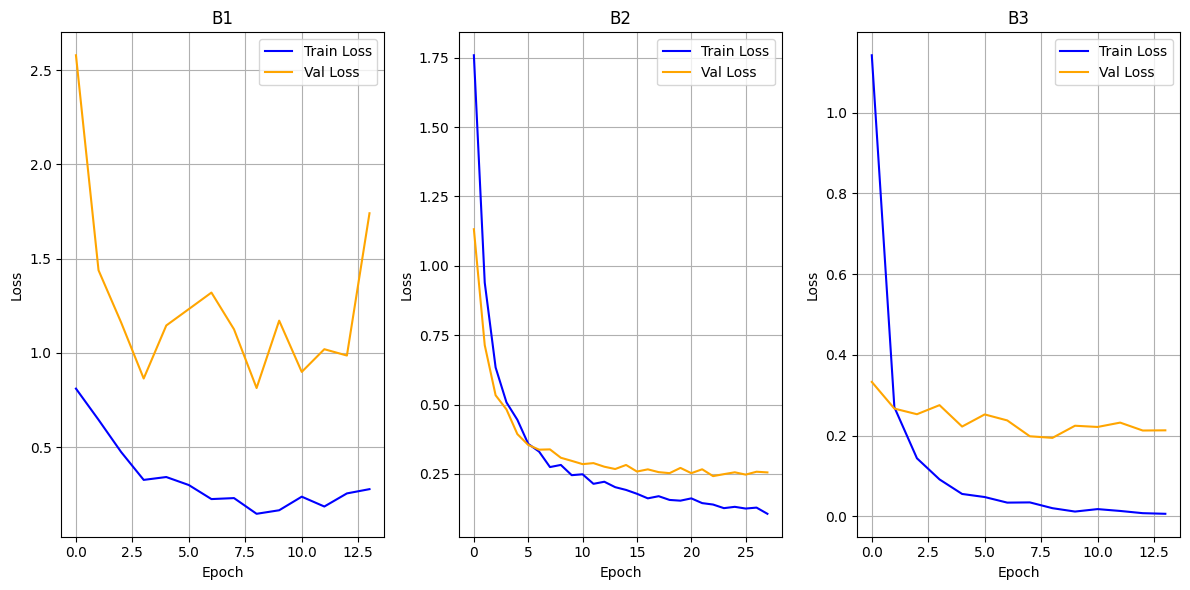

In [23]:
import pandas as pd

print("C1. Tabel Eksperimen")
print("==================================")

lr_b1 = f"{optimizer_b1.param_groups[0]['lr']:g}"
lr_b2 = f"{optimizer_b2.param_groups[0]['lr']:g}"
lr_b3 = f"{optimizer_b3.param_groups[0]['lr']:g} & {optimizer_b3.param_groups[1]['lr']:g}"
lr_b4_no = f"{optimizer_b4_no_aug.param_groups[0]['lr']:g}"
lr_b4_aug = f"{optimizer_b4_aug.param_groups[0]['lr']:g}"
lr_b5 = f"{optimizer_b5.param_groups[0]['lr']:g}"

data_c1 = {
    "Skenario": ["B1", "B2", "B3", "B4 (Tanpa aug)", "B4 (Dengan aug)", "B5"],
    "Trainable Params": [trainable_params_b1, trainable_params_b2, trainable_params_b3, trainable_params_b4_no_aug, trainable_params_b4_aug, trainable_params_b5],
    "Learning Rate": [lr_b1, lr_b2, lr_b3, lr_b4_no, lr_b4_aug, lr_b5],
    "Epoch Konvergen": [len(history_b1['train_loss']), len(history_b2['train_loss']), len(history_b3['train_loss']), len(history_b4_no_aug['train_loss']), len(history_b4_aug['train_loss']), len(history_b5['train_loss'])],
    "Waktu (detik)": [round(time_b1, 2), round(time_b2, 2), round(time_b3, 2), round(time_b4_no_aug, 2),round(time_b4_aug, 2), round(time_b5, 2)],
    "Acc" : [round(max(history_b1['val_acc']), 4), round(max(history_b2['val_acc']), 4), round(max(history_b3['val_acc']), 4), round(max(history_b4_no_aug['val_acc']), 4), round(max(history_b4_aug['val_acc']), 4), round(max(history_b5['val_acc']), 4)],
    "Macro F1": [round(f1_b1, 4), round(f1_b2, 4), round(f1_b3, 4), round(f1_b4_no_aug, 4), round(f1_b4_aug, 4), round(f1_b5, 4)]
}

df_c1 = pd.DataFrame(data_c1)
display(df_c1)

print("Kurva Loss B1, B2, B3")
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
histories = [history_b1, history_b2, history_b3]
titles = ['B1', 'B2', 'B3']

for i, (hist, title) in enumerate(zip(histories, titles)):
    axes[i].plot(hist['train_loss'], label='Train Loss', color='blue')
    axes[i].plot(hist['val_loss'], label='Val Loss', color='orange')
    axes[i].set_title(title)
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('Loss')
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

## C3. Failure Analysis (Analisis Kasus Misklasifikasi)

In [39]:
models = [
    ("B1", model_b1, acc_b1),
    ("B2", model_b2, acc_b2),
    ("B3", model_b3, acc_b3),
    ("B4", model_b4_no_aug, acc_b4_no_aug),
    ("B4", model_b4_aug, acc_b4_aug),
    ("B5", model_b5, acc_b5)
]

nama, best_model, skor_terbaik = max(models, key=lambda x: x[2])

print(f"Best Model : {nama}")
print(f"Accuracy: {skor_terbaik:.4f}")

Best Model : B3
Accuracy: 0.9396


C3. Failure Analysis (Kasus Misklasifikasi)


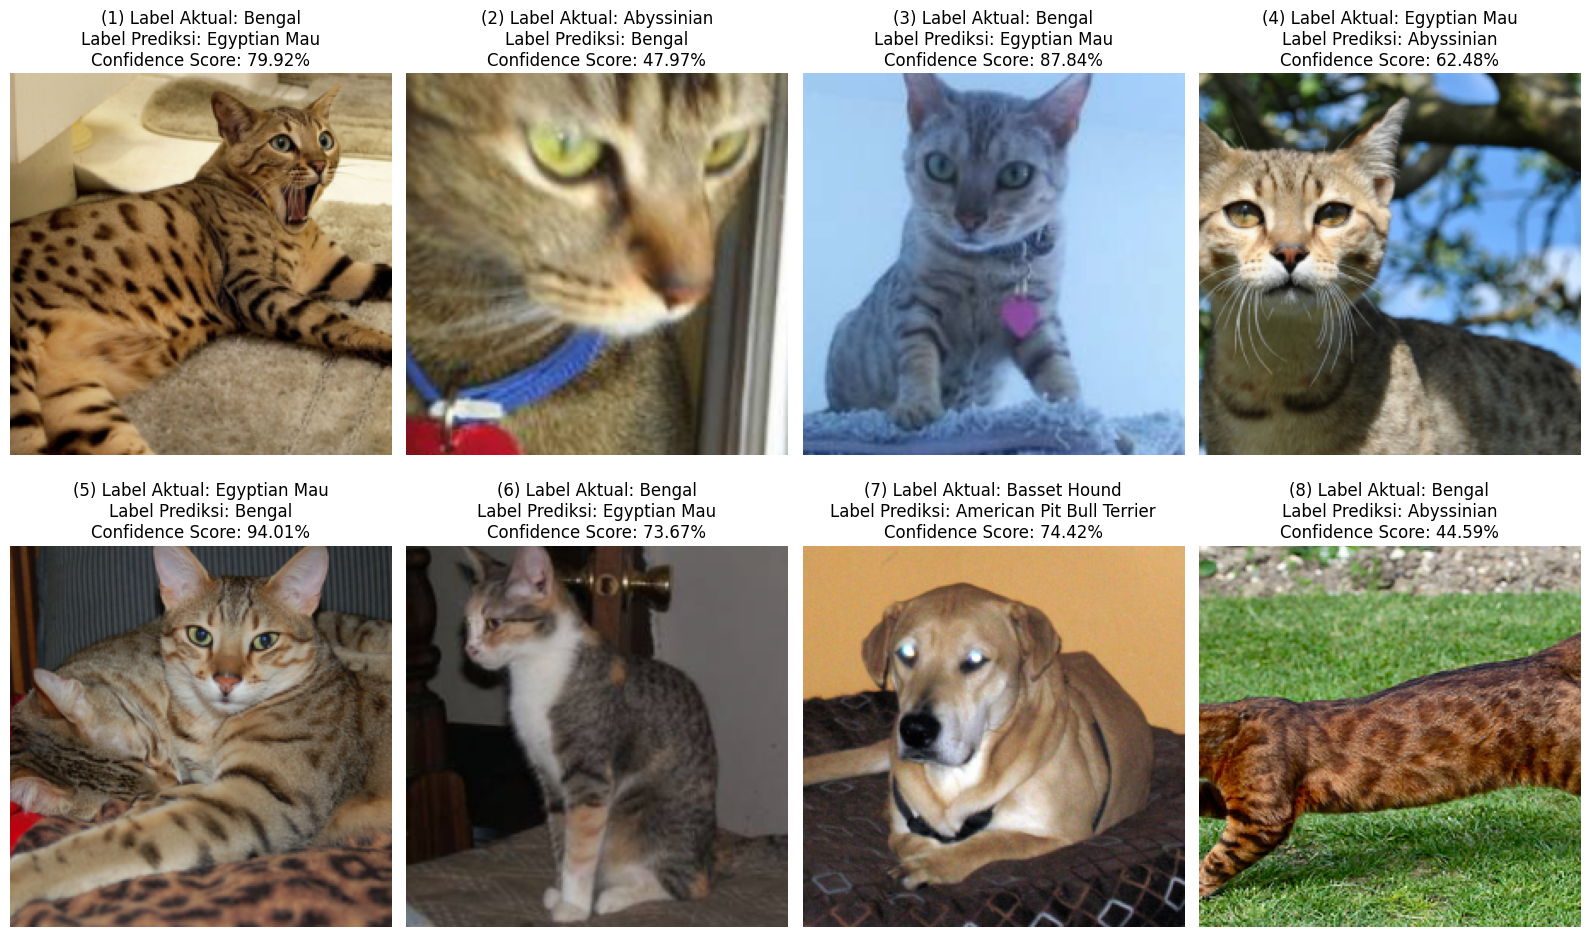

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import torch

print("C3. Failure Analysis (Kasus Misklasifikasi)")

best_model.eval()

misclassified_imgs = []
misclassified_info = []

class_names = [train_data.dataset.classes[idx] for idx in selected_class]

with torch.no_grad():
    for inputs, aktual in test_loader:
        inputs = inputs.to(device)
        aktual = aktual.to(device)
        outputs = best_model(inputs)
        prediksi = outputs.argmax(dim=1)
        persentase = torch.softmax(outputs, dim=1)
        confidences = persentase.max(dim=1).values

        for i in range(len(prediksi)):
            if aktual[i] != prediksi[i]:
                img = inputs[i].cpu().numpy().transpose((1, 2, 0))
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = np.clip(img * std + mean, 0, 1)

                misclassified_imgs.append(img)
                misclassified_info.append({
                    'true': class_names[aktual[i].item()],
                    'pred': class_names[prediksi[i].item()],
                    'conf': confidences[i].item() * 100
                })
            if len(misclassified_imgs) == 8:
                break
        if len(misclassified_imgs) == 8:
            break

fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for idx, ax in enumerate(axes.flat):
    if idx < len(misclassified_imgs):
        ax.imshow(misclassified_imgs[idx])
        info = misclassified_info[idx]
        teks = (
            f"({idx+1}) Label Aktual: {info['true']}\n"
            f"Label Prediksi: {info['pred']}\n"
            f"Confidence Score: {info['conf']:.2f}%"
        )
        ax.set_title(teks)
    ax.axis('off')

plt.tight_layout()
plt.show()

## C5. Eksplorasi Tambahan (Feature map)


C5. Eksplorasi Tambahan


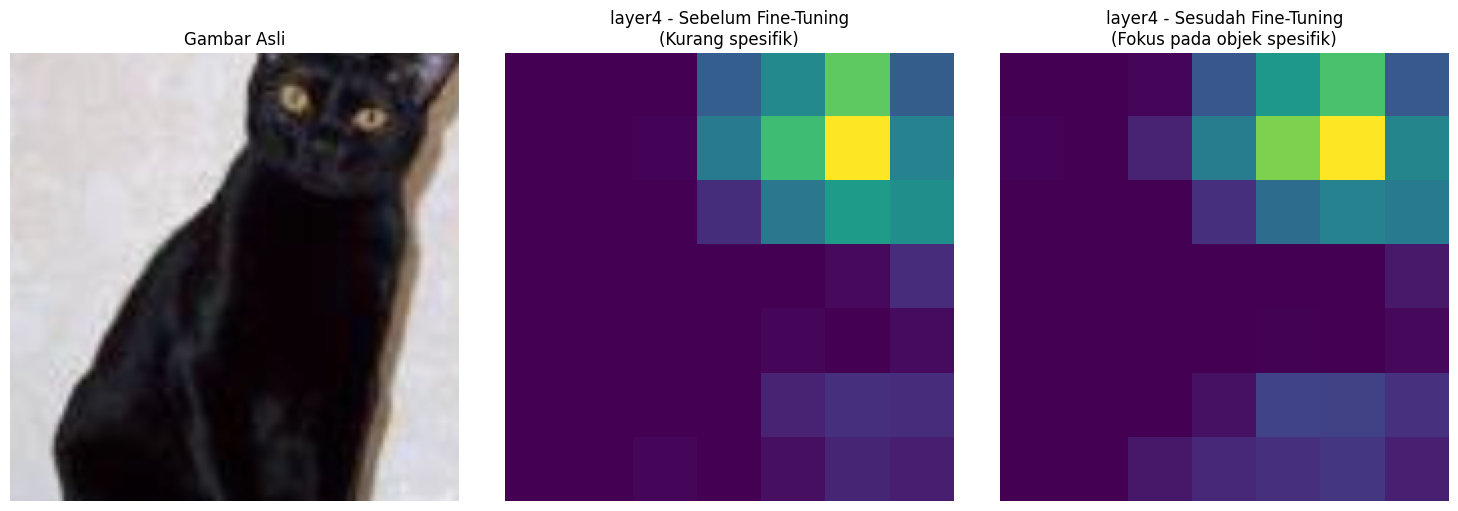

In [31]:
print("C5. Eksplorasi Tambahan")
sample_image, label_asli = test_data[0]
sample_image = sample_image.unsqueeze(0).to(device)

model_b2 = model_b2.eval()
model_b3 = model_b3.eval()

def get_layer4_features(model, x):
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    x = model.layer4(x)
    return x

with torch.no_grad():
    fitur_sebelum = get_layer4_features(model_b2, sample_image)
    fitur_setelah = get_layer4_features(model_b3, sample_image)
    map_sebelum = fitur_sebelum[0, 0].cpu().numpy()
    map_setelah = fitur_setelah[0, 0].cpu().numpy()

img_asli = sample_image[0].cpu().numpy().transpose((1, 2, 0))
img_asli = np.clip(img_asli * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_asli)
axes[0].set_title("Gambar Asli")
axes[0].axis('off')

axes[1].imshow(map_sebelum, cmap='viridis')
axes[1].set_title("layer4 - Sebelum Fine-Tuning\n(Kurang spesifik)")
axes[1].axis('off')

axes[2].imshow(map_setelah, cmap='viridis')
axes[2].set_title("layer4 - Sesudah Fine-Tuning\n(Fokus pada objek spesifik)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Log hasil mentah (json)

In [33]:
import json
import pandas as pd
from google.colab import files

logs = {
    "B1": {
        "train_loss": history_b1.get('train_loss', []),
        "val_loss": history_b1.get('val_loss', []),
        "val_acc": history_b1.get('val_acc', [])
    },
    "B2": {
        "train_loss": history_b2.get('train_loss', []),
        "val_loss": history_b2.get('val_loss', []),
        "val_acc": history_b2.get('val_acc', [])
    },
    "B3": {
        "train_loss": history_b3.get('train_loss', []),
        "val_loss": history_b3.get('val_loss', []),
        "val_acc": history_b3.get('val_acc', [])
    },
    "B4_no_aug": {
        "train_loss": history_b4_no_aug.get('train_loss', []),
        "val_loss": history_b4_no_aug.get('val_loss', []),
        "val_acc": history_b4_no_aug.get('val_acc', [])
    },
    "B4_Aug": {
        "train_loss": history_b4_aug.get('train_loss', []),
        "val_loss": history_b4_aug.get('val_loss', []),
        "val_acc": history_b4_aug.get('val_acc', [])
    },
    "B5": {
        "train_loss": history_b5.get('train_loss', []),
        "val_loss": history_b5.get('val_loss', []),
        "val_acc": history_b5.get('val_acc', [])
    }
}

filename = "training_logs.json"
with open(filename, "w") as f:
    json.dump(logs, f)